# *Concept drift* de clientes no SynCCFD

Este notebook mostra o *concept drift* de clientes do motor v2 (Fase 2 do plano
`docs/plan-v0.2.md`). Cada cliente tem um **regime A** (o perfil original); um cliente
com *drift* ganha também um **regime B**, sorteado a partir de A, e um tipo de *drift*
que define o peso de B ao longo do tempo, $w(t) \in [0, 1]$:

| tipo | $w(t)$ | como se aplica |
|---|---|---|
| súbito | 0 antes de $t_0$, 1 depois | parâmetros de B a partir de $t_0$ |
| gradual | sobe de 0 a 1 em $[t_0, t_0 + L]$ | cada transação vem de B com probabilidade $w(t)$ |
| incremental | idem | parâmetros interpolados: $\theta(t) = (1 - w)\,\theta_A + w\,\theta_B$ |
| recorrente | 1 durante $D$ dias a cada $P$ dias, a partir de $t_0$ | ex.: férias, viagens |

As figuras são gravadas em PDF em `docs/figures/fase2/`.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from synccfd import DatasetGenerator
from synccfd.simulator.config import DriftConfig, FraudConfig
from synccfd.simulator.engine.drift import CustomerDrift, regime_weight

# Where the figures are saved (the tests point this to a temporary folder)
FIG_DIR = Path(os.environ.get("SYNCCFD_FIG_DIR", "../docs/figures/fase2"))
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Validated categorical palette (see the dataviz notes in the PR): fixed order
COLOR_A, COLOR_B = "#2a78d6", "#eb6834"
TYPE_COLORS = {"sudden": "#2a78d6", "gradual": "#eb6834", "incremental": "#1baf7a", "recurrent": "#eda100"}
TYPE_NAMES = {"sudden": "súbito", "gradual": "gradual", "incremental": "incremental", "recurrent": "recorrente"}
MUTED, INK = "#8a8985", "#0b0b0b"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
    "axes.edgecolor": "#b5b4ae", "axes.labelcolor": INK, "font.size": 10,
})

## Geração

Clientes com *drift*: 30% (padrão do `DriftConfig`). As fraudes ficam **desligadas**,
para mostrar só o *drift*: com elas ligadas, o cenário 1 (limiar fixo de R$ 220) marca
como fraude as compras de clientes cujo regime B gasta mais que isso, e essas compras
somem das transações legítimas. A Fase 3 troca esse limiar fixo por um quantil.

In [2]:
N_CUSTOMERS, N_TERMINALS, NB_DAYS = 5000, 10000, 365
START_DATE, SEED = "2023-01-01", 42

drift = DriftConfig()
customers, terminals, transactions = DatasetGenerator(
    n_customers=N_CUSTOMERS, n_terminals=N_TERMINALS, nb_days=NB_DAYS,
    start_date=START_DATE, random_state=SEED, drift=drift, fraud=FraudConfig(scenarios=()),
).generate()
legit = transactions
print(f"{len(transactions):,} transações")
customers.GT_DRIFT_TYPE.value_counts().rename("clientes").to_frame()

3,648,489 transações


,clientes
GT_DRIFT_TYPE,
none,3500
gradual,457
sudden,425
incremental,312
recurrent,306


## Um cliente por tipo de *drift*

Para cada tipo, um cliente frequente (pelo menos 2,5 transações por dia em média no
regime A) com mudança grande de valor entre A e B. À esquerda, o valor de cada
transação, colorido pelo regime de origem (`GT_REGIME`), e o valor médio de cada regime
(tracejado); à direita, as transações por dia e a taxa esperada $\lambda(t)$.

In [3]:
def as_drift(row):
    # Rebuild the drift of one customer from its ground-truth columns
    def value(name):
        v = row[name]
        return 0 if pd.isna(v) else int(v)
    return CustomerDrift(kind=row.GT_DRIFT_TYPE, t0=value("GT_DRIFT_T0"),
                         transition_days=value("GT_DRIFT_L"), period_days=value("GT_DRIFT_PERIOD"),
                         active_days=value("GT_DRIFT_ACTIVE_DAYS"))


def pick_example(kind):
    pool = customers[(customers.GT_DRIFT_TYPE == kind) & (customers.mean_nb_tx_per_day >= 2.5)
                     & (customers.GT_DRIFT_T0.between(0.3 * NB_DAYS, 0.6 * NB_DAYS))]
    if kind == "recurrent":
        pool = pool[pool.GT_DRIFT_PERIOD <= 60]
    change = np.abs(np.log(pool.GT_B_mean_amount / pool.mean_amount))
    return pool.loc[change.idxmax()]


examples = {kind: pick_example(kind) for kind in TYPE_NAMES}
pd.DataFrame(examples).T[["CUSTOMER_ID", "mean_amount", "GT_B_mean_amount", "mean_nb_tx_per_day",
                          "GT_B_mean_nb_tx_per_day", "GT_DRIFT_T0", "GT_DRIFT_L", "GT_DRIFT_PERIOD",
                          "GT_DRIFT_ACTIVE_DAYS"]]

,CUSTOMER_ID,mean_amount,GT_B_mean_amount,mean_nb_tx_per_day,GT_B_mean_nb_tx_per_day,GT_DRIFT_T0,GT_DRIFT_L,GT_DRIFT_PERIOD,GT_DRIFT_ACTIVE_DAYS
sudden,742,33.483854,113.884397,2.699171,1.740945,122,<NA>,<NA>,<NA>
gradual,3530,57.446618,238.766305,3.52587,3.468322,210,29,<NA>,<NA>
incremental,1854,22.352119,7.41235,3.792664,5.638701,164,9,<NA>,<NA>
recurrent,1678,64.026126,18.994311,2.722152,2.506977,202,<NA>,57,10


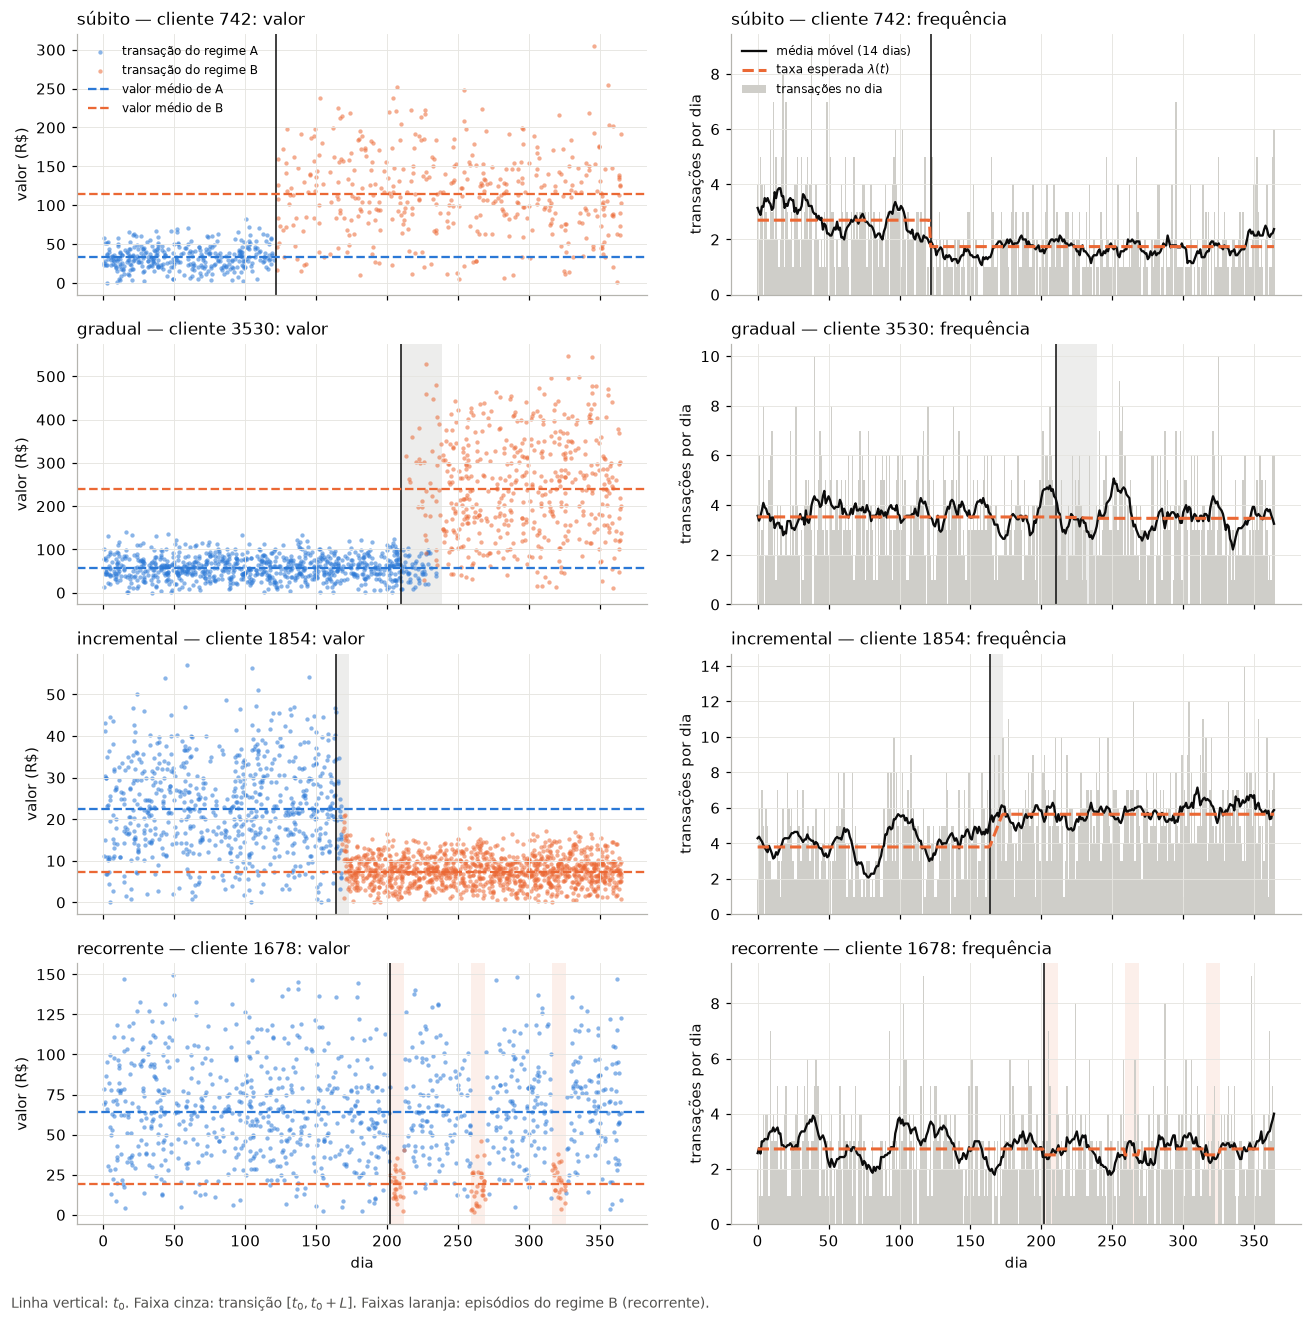

In [4]:
days = np.arange(NB_DAYS)
fig, axes = plt.subplots(4, 2, figsize=(12, 12), sharex=True)

for (kind, row), (ax_amount, ax_count) in zip(examples.items(), axes):
    own = legit[legit.CUSTOMER_ID == row.CUSTOMER_ID]
    w = regime_weight(as_drift(row), days + 0.5)

    # Marks: t0 and the transition (gradual, incremental) or the B episodes (recurrent)
    for ax in (ax_amount, ax_count):
        if kind == "recurrent":
            active = w > 0
            starts = days[active & ~np.r_[False, active[:-1]]]
            ends = days[active & ~np.r_[active[1:], False]] + 1
            for s, e in zip(starts, ends):
                ax.axvspan(s, e, color=COLOR_B, alpha=0.10, lw=0)
        elif kind in ("gradual", "incremental"):
            ax.axvspan(row.GT_DRIFT_T0, row.GT_DRIFT_T0 + row.GT_DRIFT_L, color=MUTED, alpha=0.15, lw=0)
        ax.axvline(row.GT_DRIFT_T0, color=INK, lw=1.0, ls="-")

    for regime, color in (("A", COLOR_A), ("B", COLOR_B)):
        part = own[own.GT_REGIME == regime]
        ax_amount.scatter(part.TX_TIME_SECONDS / 86400, part.TX_AMOUNT, s=8, color=color,
                          alpha=0.55, lw=0, label=f"transação do regime {regime}")
    ax_amount.axhline(row.mean_amount, color=COLOR_A, lw=1.5, ls="--", label="valor médio de A")
    ax_amount.axhline(row.GT_B_mean_amount, color=COLOR_B, lw=1.5, ls="--", label="valor médio de B")
    ax_amount.set_ylabel("valor (R$)")
    ax_amount.set_title(f"{TYPE_NAMES[kind]} — cliente {row.CUSTOMER_ID}: valor", loc="left", fontsize=11)

    per_day = own.groupby("TX_TIME_DAYS").size().reindex(days, fill_value=0)
    expected = (1 - w) * row.mean_nb_tx_per_day + w * row.GT_B_mean_nb_tx_per_day
    ax_count.bar(days, per_day, width=1.0, color="#cfcec9", lw=0, label="transações no dia")
    ax_count.plot(days, per_day.rolling(14, center=True, min_periods=1).mean(), color=INK, lw=1.5,
                  label="média móvel (14 dias)")
    ax_count.plot(days, expected, color=COLOR_B, lw=2, ls="--", label=r"taxa esperada $\lambda(t)$")
    ax_count.set_ylabel("transações por dia")
    ax_count.set_title(f"{TYPE_NAMES[kind]} — cliente {row.CUSTOMER_ID}: frequência", loc="left", fontsize=11)

for ax in axes[-1]:
    ax.set_xlabel("dia")
axes[0, 0].legend(loc="upper left", fontsize=8, frameon=False)
axes[0, 1].legend(loc="upper left", fontsize=8, frameon=False)
fig.text(0.01, 0.005, "Linha vertical: $t_0$. Faixa cinza: transição $[t_0, t_0+L]$. "
         "Faixas laranja: episódios do regime B (recorrente).", fontsize=9, color="#52514e")
fig.tight_layout(rect=(0, 0.02, 1, 1))
fig.savefig(FIG_DIR / "drift_exemplos_clientes.pdf", bbox_inches="tight")
plt.show()

## Fração em B ao longo do tempo

Peso médio do regime B, $\bar w(t)$, entre os clientes de cada tipo, e entre todos os
clientes (inclusive os sem *drift*). Para os tipos súbito e recorrente, $w \in \{0, 1\}$
e $\bar w(t)$ é a fração de clientes em B.

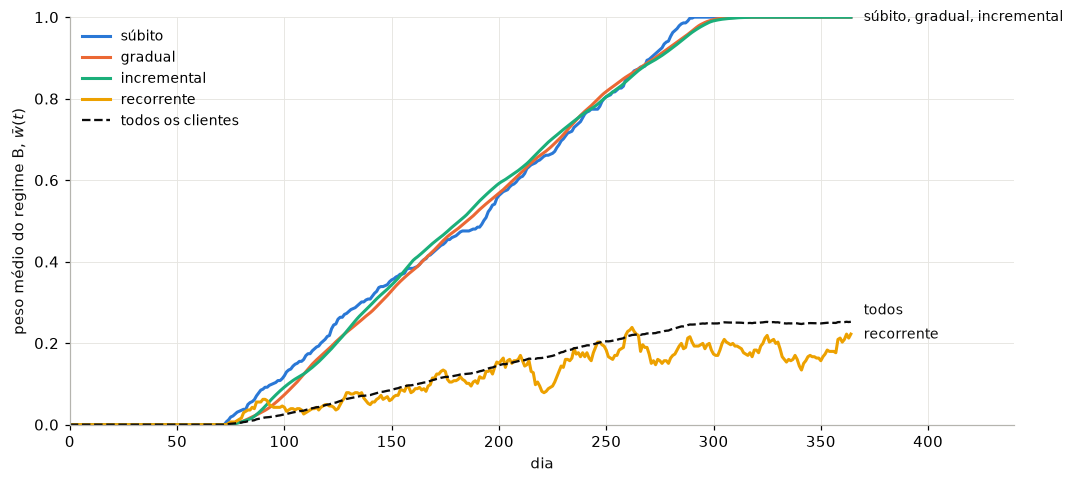

In [5]:
weights = np.vstack([regime_weight(as_drift(row), days + 0.5) for _, row in customers.iterrows()])
kinds = customers.GT_DRIFT_TYPE.to_numpy()

fig, ax = plt.subplots(figsize=(10, 4.5))
ends = {}
for kind, color in TYPE_COLORS.items():
    share = weights[kinds == kind].mean(axis=0)
    ax.plot(days, share, color=color, lw=2, label=TYPE_NAMES[kind])
    ends.setdefault(round(share[-1], 2), []).append(TYPE_NAMES[kind])
overall = weights.mean(axis=0)
ax.plot(days, overall, color=INK, lw=1.5, ls="--", label="todos os clientes")
ends.setdefault(round(overall[-1], 2), []).append("todos")
# Direct labels at the right end; lines ending at the same value share one label
placed = []
for value, names in sorted(ends.items()):
    y = max([value] + [p + 0.06 for p in placed if abs(p - value) < 0.06])
    placed.append(y)
    ax.annotate(", ".join(names), (days[-1], value), xytext=(days[-1] + 6, y),
                textcoords="data", va="center", fontsize=9, color=INK)
ax.set_xlim(0, NB_DAYS + 75)
ax.set_ylim(0, 1)
ax.set_xlabel("dia")
ax.set_ylabel(r"peso médio do regime B, $\bar w(t)$")
ax.legend(loc="upper left", frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "drift_fracao_regime_b.pdf", bbox_inches="tight")
plt.show()

## Quanto o regime B difere de A

Distribuição das mudanças sorteadas para os clientes com *drift*: razão entre os valores
médios e entre as frequências (escala log) e diferença na probabilidade de CNP.

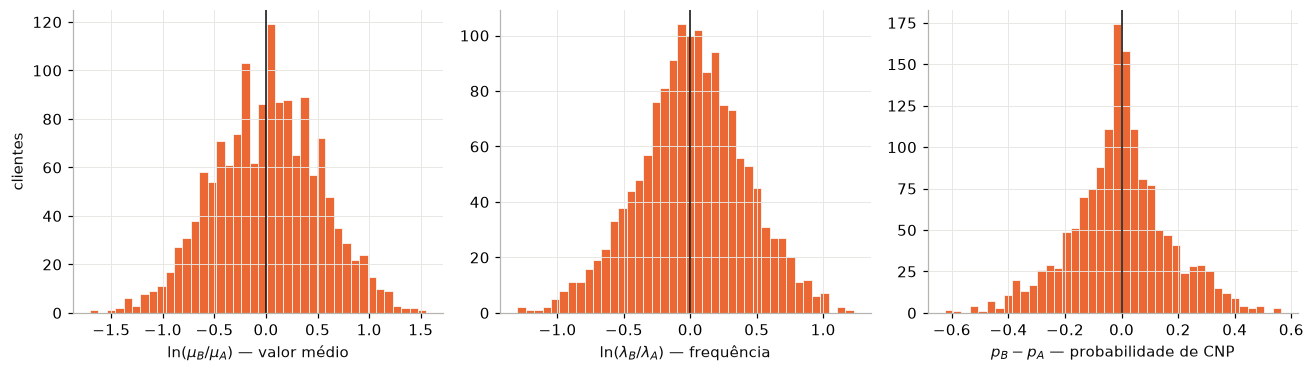

,clientes,mudou_de_cidade,mudanca_media_valor_log
GT_DRIFT_TYPE,,,
gradual,457,19,0.419535
incremental,312,18,0.420717
recurrent,306,17,0.390302
sudden,425,19,0.425170


In [6]:
drifting = customers[customers.GT_DRIFT_TYPE != "none"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
series = [
    (np.log(drifting.GT_B_mean_amount / drifting.mean_amount), r"$\ln(\mu_B / \mu_A)$ — valor médio"),
    (np.log(drifting.GT_B_mean_nb_tx_per_day / drifting.mean_nb_tx_per_day), r"$\ln(\lambda_B / \lambda_A)$ — frequência"),
    (drifting.GT_B_cnp_prob - drifting.cnp_prob, r"$p_B - p_A$ — probabilidade de CNP"),
]
for ax, (values, label) in zip(axes, series):
    ax.hist(values, bins=40, color=COLOR_B, edgecolor="#fcfcfb", linewidth=0.5)
    ax.axvline(0, color=INK, lw=1)
    ax.set_xlabel(label)
axes[0].set_ylabel("clientes")
fig.tight_layout()
fig.savefig(FIG_DIR / "drift_parametros_regime_b.pdf", bbox_inches="tight")
plt.show()

summary = drifting.assign(
    amount_change=np.abs(np.log(drifting.GT_B_mean_amount / drifting.mean_amount)),
).groupby("GT_DRIFT_TYPE").agg(clientes=("CUSTOMER_ID", "size"), mudou_de_cidade=("GT_RELOCATED", "sum"),
                                 mudanca_media_valor_log=("amount_change", "mean"))
summary